# 01 · Real liquid activities and gE with SAFT and COSMO-RS

The main course uses actual ThermoWeave models and real chemical components. See the [course index](../tutorials.md).

<a class="md-button" href="01_excess_gibbs_models.ipynb" download>Download notebook</a>


For real water + ethanol, compute $a_i=x_i\gamma_i$,
$g^E/(RT)=\sum_i x_i\ln\gamma_i$ and
$g_{mix}/(RT)=\sum_i x_i\ln x_i+g^E/(RT)$.
SAFT obtains liquid activities from fugacity ratios in the pure-liquid standard
state. COSMO-RS supplies liquid activities directly through its adapter.
These are actual model calculations with unchanged parameters; the equations
are not evaluated using a synthetic Margules approximation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
names=['water','ethanol'];T=298.15
model=SAFTgammaMie.from_smiles({'water':'O','ethanol':'CCO'},pressure_Pa=101325.)
x=np.array([.8,.2])
lng=model.ln_activity_coefficients(T,x)
print('ln gamma:',lng)
print('activities:',model.activities(T,x))
print('gE/RT:',model.reduced_excess_gibbs(T,x))
print('g_mix/RT:',model.reduced_mixing_gibbs(T,x))
np.testing.assert_allclose(model.reduced_excess_gibbs(T,x),x@lng)

SAFT-gamma-Mie automatic assignment: water
  SMILES: O
  Formula: H2O
  Groups: {'H2O': 1}
  Atom-labelled SMILES (labels are 1-based): [OH2:1]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  H2O x1:
    atoms 1:O(H2)
    rule: whole water molecule; SMARTS [O;H2;X2]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 1/1 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


SAFT-gamma-Mie automatic assignment: ethanol
  SMILES: CCO
  Formula: C2H6O
  Groups: {'CH2OH': 1, 'CH3': 1}
  Atom-labelled SMILES (labels are 1-based): [CH3:1][CH2:2][OH:3]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  CH2OH x1:
    atoms 2:C(H2), 3:O(H1)
    rule: primary alcohol carbon plus hydroxyl; SMARTS [C;!R;H2;X4]-[O;H1;X2]
    parameters: 10.1021/acs.jced.0c00746
  CH3 x1:
    atoms 1:C(H3)
    rule: acyclic saturated methyl carbon; SMARTS [C;!R;H3;X4]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 3/3 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


ln gamma: [0.07061374 0.72796927]
activities: [0.8585333  0.41417419]
gE/RT: 0.2020848480842691
g_mix/RT: -0.29831757545391874


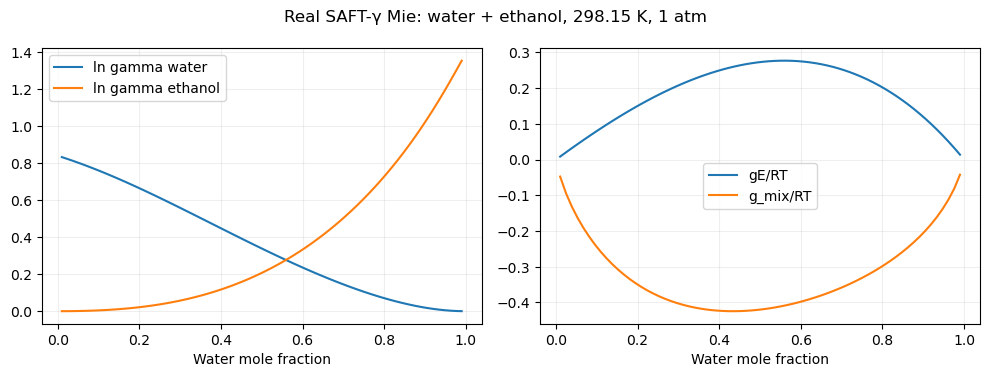

In [2]:
xs=np.linspace(.01,.99,70);X=np.column_stack([xs,1-xs])
lng=model.ln_activity_coefficients_batch(T,X)
ge=np.sum(X*lng,axis=1)
gmix=np.sum(X*np.log(X),axis=1)+ge
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
ax[0].plot(xs,lng[:,0],label='ln gamma water');ax[0].plot(xs,lng[:,1],label='ln gamma ethanol')
ax[1].plot(xs,ge,label='gE/RT');ax[1].plot(xs,gmix,label='g_mix/RT')
for a in ax:a.set_xlabel('Water mole fraction');a.grid(alpha=.2);a.legend()
fig.suptitle('Real SAFT-γ Mie: water + ethanol, 298.15 K, 1 atm');fig.tight_layout();plt.show()

## Use the same calls with a real COSMO-RS model
When the external conformers and engine are configured, the following cell
constructs the actual adapter and evaluates it. Without inputs it prints setup
instructions; it never replaces COSMO-RS with a toy model. Notebooks 09 and 13
contain saved output from actual executions with those inputs.

In [3]:
import os
if os.environ.get('THERMOWEAVE_COSMO_ROOT'):
    from thermoweave import build_cosmors_model
    from _support import cosmo_components
    definitions,manifest=cosmo_components(names)
    cosmo=build_cosmors_model(os.environ.get('THERMOWEAVE_COSMO_PARAMETERS','default_turbomole'),definitions)
    print('Real COSMO-RS ln gamma:',cosmo.ln_activity_coefficients(T,x))
    print('Real COSMO-RS gE/RT:',cosmo.reduced_excess_gibbs(T,x))
else:
    print('COSMO-RS comparison needs external data; configure notebook 09. SAFT results above are actual calculations.')

COSMO-RS comparison needs external data; configure notebook 09. SAFT results above are actual calculations.


For a small analytic derivation of activity coefficients from a chosen
scalar gE function, see the optional [custom-model theory notebook](theory/custom_activity_models.ipynb).
The main application course uses the existing physical models.